# Price returns of stocks

The subject is the distribution of daily equity returns in the project database: what a single
security's returns look like, and how securities move together. It is descriptive work. Nothing here
forecasts a return or ranks a security; the aim is to establish what the data actually contains before
any model is fitted to it.

Sections 2 and 3 treat each security on its own, measuring the shape of its return distribution and the
memory in its volatility. Sections 4 and 5 treat the cross-section, measuring how much of a security's
movement is shared with every other security. Section 4 overlaps `8_pca_weights.ipynb`, which takes the
correlation structure considerably further: Marcenko-Pastur noise fitting, denoising and detoning,
eigenportfolios, and split-half stability of the eigenvectors. What appears here is the summary view,
kept so this notebook stands on its own; notebook 8 is the reference for anything beyond it.

The database access goes through `panels.py` and the eigendecomposition through `eigen.py`, the same
modules notebook 8 uses. Only the distribution mathematics is new, and it is defined in this notebook
because it is vectorized across the whole panel rather than applied one series at a time.

> ### Survivorship
>
> `prices` holds no delisted securities. Every company that went bankrupt, was acquired, or was
> otherwise removed from its exchange is absent, because the ticker list was seeded from currently
> listed symbols. This is recorded as an open finding in `9999_data_quirks.ipynb`.
>
> The consequence is specific and it is not small. Every statistic below is conditional on survival to
> 2026, and the conditioning tightens the further back the window reaches: a security must have lasted
> the whole period to appear at all. What gets removed is the left tail, so measured skewness is too
> favourable, measured drawdowns too shallow, and the frequency of catastrophic returns too low.
> Section 1 measures the size of the gap. Read every downside number as an upper bound on how good
> things were.

In [1]:
%load_ext autoreload
%autoreload 2
import eigen
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from helpers import connect_readonly, plot_scree, show_df, show_note
from scipy import stats as sps

from investalyze.analysis import panels
from investalyze.apps import universes

plt.rcParams['figure.dpi'] = 130
con = connect_readonly()
print('saved universes available:', universes.list_universes())

saved universes available: ['0_to_check', 'BL_shell_companies', 'BL_unknown_sector', 'mid_large_mega_non_fin_realest', 'solar_small_mid_large']


## Parameters

Every setting is in the cell below. Changing one requires re-running from that cell downward.

### Which securities enter the panel

Notebook 8 needs a complete price history for every security, because a correlation matrix cannot be
estimated from a ragged panel without a fill policy. Distribution work has no such constraint, and
imposing one would be actively harmful: requiring twenty-one years of unbroken history would keep only
the longest-lived survivors, stacking a second selection on top of the survivorship already present.

`MIN_OBS_FRAC` therefore sets a floor rather than a requirement. At the default of 0.2 a security joins
once it is priced on a fifth of the calendar, which at a 2005 start is a little over four years of
history: enough for a moment estimate to mean something, loose enough to keep recent listings.

### Turnover

A security that does not trade on a session has no new price, so the previous close is carried forward
and the panel records a return of exactly zero. That zero is not a measurement. It is the single most
important contaminant of the statistics below, and section 1 quantifies how it varies with turnover.
`MIN_ADV` can exclude the least traded securities; it ships disabled so that nothing is dropped
silently.

In [2]:
START        = '2005-01-01'   # first session of the panel; None starts at the earliest available
END          = None           # last session of the panel; None ends at the most recent available

MIN_OBS_FRAC = 0.2            # a security joins once priced on this share of the calendar
MIN_ADV      = 0.0            # minimum median daily turnover (close x volume) to enter; 0 disables

HORIZONS     = (1, 5, 21, 63) # holding periods, in sessions, for the aggregation study in section 2
SCATTER_H    = 21             # horizon for the mean-vs-median scatter; see that section for why not 1

BENCHMARK    = '^NDX'         # index beta is measured against. '^NDX' and '^NDQ' run to the present;
                              # '^SPX' stops at 2026-07-02 and would cover only part of the window.
PCA_START    = '2021-08-01'   # section 4 needs complete series, so it uses its own shorter window
PCA_N_TOP    = 400            # securities in that correlation study, matching notebook 8

SELECTION    = 'solar_small_mid_large'  # securities labelled on the scatter. A string names a saved
                              # universe in data/universes/, a list names them directly.
ACF_LAGS     = (*range(1, 21), 25, 30, 40, 50, 63)   # lags for the autocorrelation study in section 3
ACF_MAX      = 2000           # securities sampled for it; the median across them is what is plotted
VOL_WINDOW   = 63             # sessions in the realized-volatility window of section 3
SEED         = 0

rng = np.random.default_rng(SEED)
selection = universes.load_universe(SELECTION) if isinstance(SELECTION, str) else list(SELECTION)
print(f'selection ({len(selection)}): {", ".join(selection)}')

selection (7): ARRY, ENPH, FSLR, NXT, RUN, SEDG, SHLS


## 1. Sample

The calendar comes from `panels.trading_calendar`, which admits a session only when the number of
securities priced on it is large relative to the sessions around it. The reason is set out in section 2
of notebook 8: the distinct dates in `prices` include market holidays carrying a handful of stray rows,
and taking them at face value would record a gap for nearly every security on every holiday. Returns
are then differenced on that calendar by `panels.returns_panel`, so a one-session hole produces two
missing returns rather than one spliced two-day move.

In [3]:
calendar = panels.trading_calendar(con, start=START, end=END)
all_tickers = con.execute('SELECT DISTINCT Ticker FROM prices ORDER BY Ticker').df()['Ticker'].tolist()
closes = panels.close_panel(con, all_tickers, calendar, min_obs_frac=MIN_OBS_FRAC)

turnover = con.execute("""
    SELECT Ticker, median(C * V) AS turnover
    FROM prices
    WHERE AC IS NOT NULL AND AC > 0 AND Date IN (SELECT unnest(?::DATE[]))
    GROUP BY Ticker
""", [list(calendar.date)]).df().set_index('Ticker')['turnover']

if MIN_ADV > 0:
    keep = [t for t in closes.columns if turnover.get(t, 0.0) >= MIN_ADV]
    closes = closes[keep]

returns  = panels.returns_panel(closes, kind='log')
tickers  = returns.columns.to_numpy()
turnover = turnover.reindex(tickers)
R        = returns.to_numpy()
mask     = np.isfinite(R)
n_obs    = mask.sum(axis=0)

print(f'calendar            {calendar.min().date()} to {calendar.max().date()}, {len(calendar):,} sessions')
print(f'securities          {len(tickers):,} of {len(all_tickers):,} in prices, at MIN_OBS_FRAC={MIN_OBS_FRAC}')
print(f'returns             {R.shape[0]:,} sessions x {R.shape[1]:,} securities, {mask.mean():.1%} observed')
print(f'history per security  median {int(np.median(n_obs)):,} sessions, '
      f'shortest {n_obs.min():,}, longest {n_obs.max():,}')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

calendar            2005-01-03 to 2026-08-12, 5,436 sessions
securities          5,175 of 6,431 in prices, at MIN_OBS_FRAC=0.2
returns             5,435 sessions x 5,175 securities, 68.4% observed
history per security  median 4,092 sessions, shortest 1,087, longest 5,435


### How much of the market is missing

Two views of the same absence. The first counts securities priced on each session across the whole
history: it rises steadily, but every security in that count is one that still exists today, so the
early years show not how many securities were listed then but how many of today's survivors already
existed. The second counts securities whose price history stops before the present.

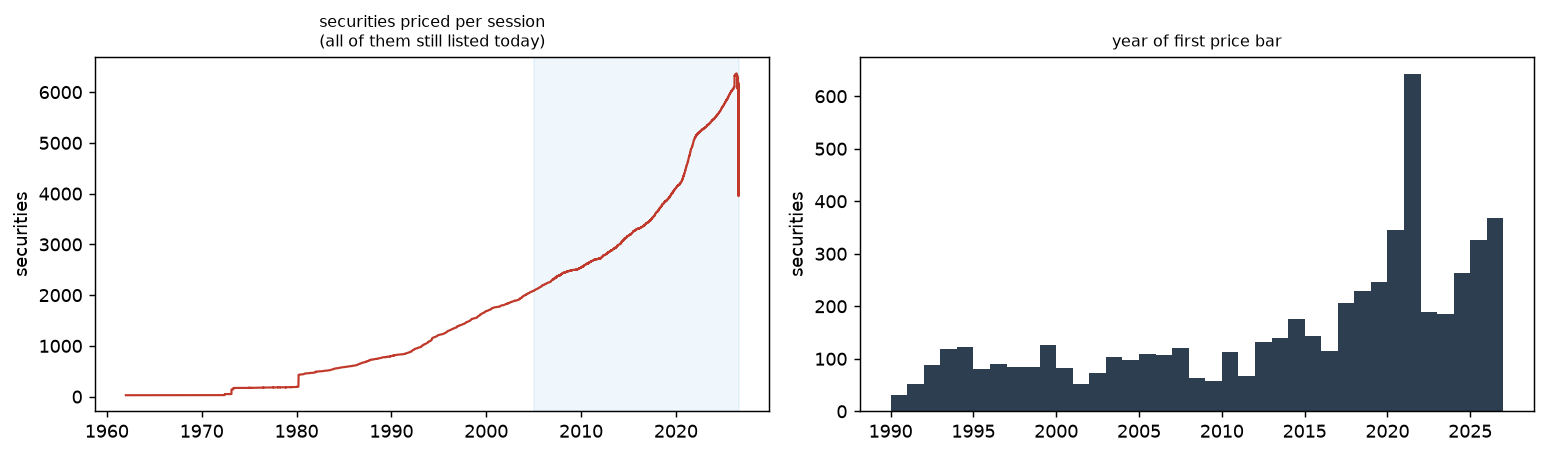

securities in prices                6,431
  still priced at 2026-08-12         6,340
  stopped before then               91  (1.42%)

Over two decades a realistic delisting rate is above 40%. This database shows 1.42%.
The difference is the measure of what is missing, not a fact about the market.


In [4]:
full_calendar = panels.trading_calendar(con)
counts = con.execute("""
    SELECT Date, count(*) AS n FROM prices WHERE AC IS NOT NULL AND AC > 0 GROUP BY Date ORDER BY Date
""").df()
listed = (counts.assign(Date=pd.DatetimeIndex(counts['Date'])).set_index('Date')['n']
          .reindex(full_calendar).dropna())

span = con.execute("""
    SELECT Ticker, min(Date) AS first_date, max(Date) AS last_date, count(*) AS sessions
    FROM prices WHERE AC IS NOT NULL AND AC > 0 GROUP BY Ticker
""").df()
last_session = span['last_date'].max()
span['dead'] = span['last_date'] < (last_session - pd.Timedelta(days=30))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(listed.index, listed.to_numpy(), color='#c0392b', lw=1.2)
axes[0].axvspan(pd.Timestamp(START), listed.index.max(), color='#3498db', alpha=0.08)
axes[0].set_title('securities priced per session\n(all of them still listed today)', fontsize=9)
axes[0].set_ylabel('securities')
first_years = pd.DatetimeIndex(span['first_date']).year
axes[1].hist(first_years[first_years >= 1990], bins=range(1990, 2028), color='#2c3e50')
axes[1].set_title('year of first price bar', fontsize=9)
axes[1].set_ylabel('securities')
fig.tight_layout()
plt.show()

n_dead = int(span['dead'].sum())
print(f'securities in prices                {len(span):,}')
print(f'  still priced at {str(last_session)[:10]}         {len(span) - n_dead:,}')
print(f'  stopped before then               {n_dead:,}  ({n_dead / len(span):.2%})')
print(f'\nOver two decades a realistic delisting rate is above 40%. This database shows '
      f'{n_dead / len(span):.2%}.')
print('The difference is the measure of what is missing, not a fact about the market.')

### Turnover and the carried-forward close

The table below splits the panel into ten groups by median daily turnover and reports, for each, how
often a return of exactly zero appears, how often that leaves the median return itself at exactly zero,
and how fat the tails are. The pattern is monotone and steep. Illiquid securities do not merely add
noise: they change the shape of every statistic, because a stale price is recorded as a return of zero
rather than as the absence of a measurement it really is.

This is why the mean-versus-median scatter later in the notebook is drawn on monthly returns.

In [5]:
med_daily = np.nanmedian(R, axis=0)
flat_share = (R == 0).sum(axis=0) / n_obs
turn = turnover.to_numpy()
valid = np.isfinite(turn) & (turn > 0)
edges = np.quantile(turn[valid], np.linspace(0, 1, 11))

rows = []
for i in range(10):
    upper = turn <= edges[i + 1] if i == 9 else turn < edges[i + 1]
    sel = valid & (turn >= edges[i]) & upper
    if not sel.sum():
        continue
    block = R[:, sel]
    rows.append({'decile': i + 1, 'min turnover': edges[i], 'securities': int(sel.sum()),
                 'zero-return days': float(flat_share[sel].mean()),
                 'median return is zero': float((med_daily[sel] == 0).mean()),
                 'median excess kurtosis': float(np.nanmedian(sps.kurtosis(block, axis=0, nan_policy='omit'))),
                 'median ann. volatility': float(np.nanmedian(np.nanstd(block, axis=0, ddof=1)) * np.sqrt(252))})

show_note('Deciles of median daily turnover, least traded first.')
show_df(pd.DataFrame(rows).set_index('decile'), decimals=4)
print(f'{(med_daily == 0).mean():.1%} of all securities have a median daily return of exactly zero.')

*Deciles of median daily turnover, least traded first.*

,min turnover,securities,zero-return days,median return is zero,median excess kurtosis,median ann. volatility
decile,,,,,,
1,6.5352,511,0.2342,0.9256,28.1681,0.9040
2,"55,165.4992",510,0.0980,0.6588,29.4450,0.8867
3,"163,175.0014",511,0.0692,0.5930,26.2464,0.6102
4,"388,139.2362",510,0.0532,0.5510,25.0667,0.4754
5,"979,638.9973",511,0.0423,0.5049,20.0521,0.4695
6,"2,183,851.4935",511,0.0314,0.4736,16.8985,0.4961
7,"5,132,146.3863",510,0.0206,0.3765,15.1681,0.4812
8,"11,572,061.6367",510,0.0149,0.2510,13.5475,0.4539
9,"26,951,285.6818",511,0.0111,0.1800,12.4021,0.4125


46.2% of all securities have a median daily return of exactly zero.


## 2. The return distribution

Each security's returns are reduced to four numbers: mean, standard deviation, skewness and excess
kurtosis. What follows is the distribution of each of those numbers across securities, which is a
different object from the distribution of returns and carries different information. A single pooled
histogram would show the average shape while hiding how much securities differ from one another.

Excess kurtosis is reported throughout, meaning kurtosis minus 3, so that a normal distribution sits at
zero rather than at three.

In [6]:
def col_moments(X: np.ndarray, present: np.ndarray, n: np.ndarray) -> dict[str, np.ndarray]:
    """Per-column mean, sd, skewness, excess kurtosis and median of a matrix with missing cells.

    Accumulated directly with the gaps masked to zero, because applying a one-series routine across
    thousands of columns is the wrong shape for a panel this size. `n` counts the present cells per
    column, so every moment divides by the observations that column actually has.
    """
    Z = np.where(present, X, 0.0)
    mean = Z.sum(axis=0) / n
    d = np.where(present, X - mean, 0.0)
    m2 = (d ** 2).sum(axis=0) / n
    m3 = (d ** 3).sum(axis=0) / n
    m4 = (d ** 4).sum(axis=0) / n
    with np.errstate(divide='ignore', invalid='ignore'):
        sd = np.sqrt(m2 * n / (n - 1))
        skew = m3 / m2 ** 1.5
        exkurt = m4 / m2 ** 2 - 3.0
    return {'n': n, 'mean': mean, 'sd': sd, 'skew': skew, 'exkurt': exkurt,
            'median': np.nanmedian(X, axis=0)}


def block_returns(X: np.ndarray, h: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Non-overlapping `h`-session log returns, as (values, present, count-per-column).

    A block counts only when all `h` sessions inside it are present, so no block return is a partial
    sum quietly spanning a gap.
    """
    if h == 1:
        present = np.isfinite(X)
        return X, present, present.sum(axis=0)
    n_blocks = int(X.shape[0] / h)
    blocks = X[:n_blocks * h].reshape(n_blocks, h, X.shape[1])
    present = np.isfinite(blocks).all(axis=1)
    return np.where(present, np.nansum(blocks, axis=1), np.nan), present, present.sum(axis=0)


def col_autocorr(X: np.ndarray, present: np.ndarray, lag: int, min_n: int = 30) -> np.ndarray:
    """Per-column autocorrelation at `lag`, over the observations present at both ends of it."""
    both = present[:-lag] & present[lag:]
    n = both.sum(axis=0)
    x = np.where(both, X[:-lag], 0.0)
    y = np.where(both, X[lag:], 0.0)
    sx, sy = x.sum(axis=0), y.sum(axis=0)
    sxx, syy, sxy = (x * x).sum(axis=0), (y * y).sum(axis=0), (x * y).sum(axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        num = n * sxy - sx * sy
        den = np.sqrt((n * sxx - sx ** 2) * (n * syy - sy ** 2))
        return np.where((n >= min_n) & (den > 0), num / den, np.nan)


mom = col_moments(R, mask, n_obs)
stats = pd.DataFrame({
    'sessions': mom['n'], 'ann. return': mom['mean'] * 252, 'ann. volatility': mom['sd'] * np.sqrt(252),
    'skewness': mom['skew'], 'excess kurtosis': mom['exkurt'], 'median daily': mom['median'],
    'turnover': turnover.to_numpy(),
}, index=pd.Index(tickers, name='Ticker'))

show_note('Per-security statistics, described across securities.')
show_df(stats.drop(columns='turnover').describe(percentiles=[.05, .25, .5, .75, .95]), decimals=4)

*Per-security statistics, described across securities.*

,sessions,ann. return,ann. volatility,skewness,excess kurtosis,median daily
count,"5,175.0000","5,175.0000","5,175.0000","5,175.0000","5,175.0000","5,175.0000"
mean,"3,717.4226",-0.1002,0.6257,-0.1512,49.2523,-0.0003
std,"1,716.4410",0.4160,0.4435,2.9907,110.4161,0.0016
min,"1,087.0000",-5.6420,0.0741,-35.0479,1.0996,-0.0134
5%,"1,231.0000",-0.8314,0.1774,-3.6873,4.9392,-0.0036
25%,"1,886.0000",-0.1101,0.3374,-0.7447,9.7021,0.0000
50%,"4,092.0000",0.0384,0.4895,-0.1496,17.7694,0.0000
75%,"5,435.0000",0.0882,0.7950,0.3418,44.1386,0.0005
95%,"5,435.0000",0.1758,1.4437,3.2666,201.1460,0.0009
max,"5,435.0000",2.3798,4.7675,51.9046,"3,385.7991",0.0029


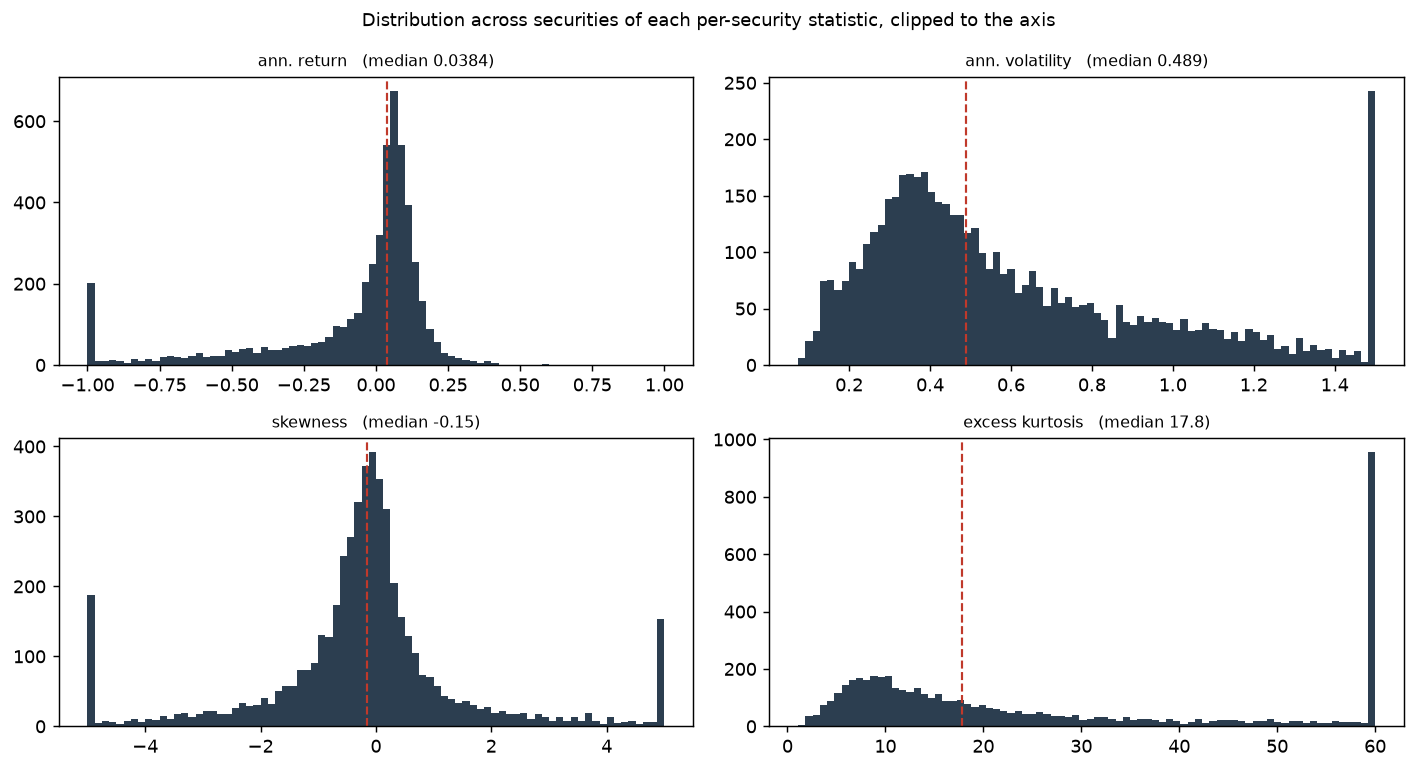

median excess kurtosis 17.8, against 0 for a normal; 99% of securities exceed 3
skewness is negative for 59% of securities


In [7]:
specs = [('ann. return', (-1.0, 1.0)), ('ann. volatility', (0.0, 1.5)),
         ('skewness', (-5, 5)), ('excess kurtosis', (0, 60))]
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (col, clip) in zip(axes.ravel(), specs):
    v = stats[col].to_numpy()
    v = v[np.isfinite(v)]
    ax.hist(np.clip(v, *clip), bins=80, color='#2c3e50')
    ax.axvline(float(np.median(v)), color='#c0392b', ls='--', lw=1.2)
    ax.set_title(f'{col}   (median {np.median(v):.3g})', fontsize=9)
fig.suptitle('Distribution across securities of each per-security statistic, clipped to the axis',
             fontsize=10)
fig.tight_layout()
plt.show()

print(f"median excess kurtosis {stats['excess kurtosis'].median():.1f}, against 0 for a normal; "
      f"{(stats['excess kurtosis'] > 3).mean():.0%} of securities exceed 3")
print(f"skewness is negative for {(stats['skewness'] < 0).mean():.0%} of securities")

The tails are the point. A normal distribution fitted to these returns is not slightly wrong at the
extremes, it is wrong by orders of magnitude, and the table under the chart puts the discrepancy in
units that mean something: how long a normal distribution says you would wait for a move that this
panel produces routinely.

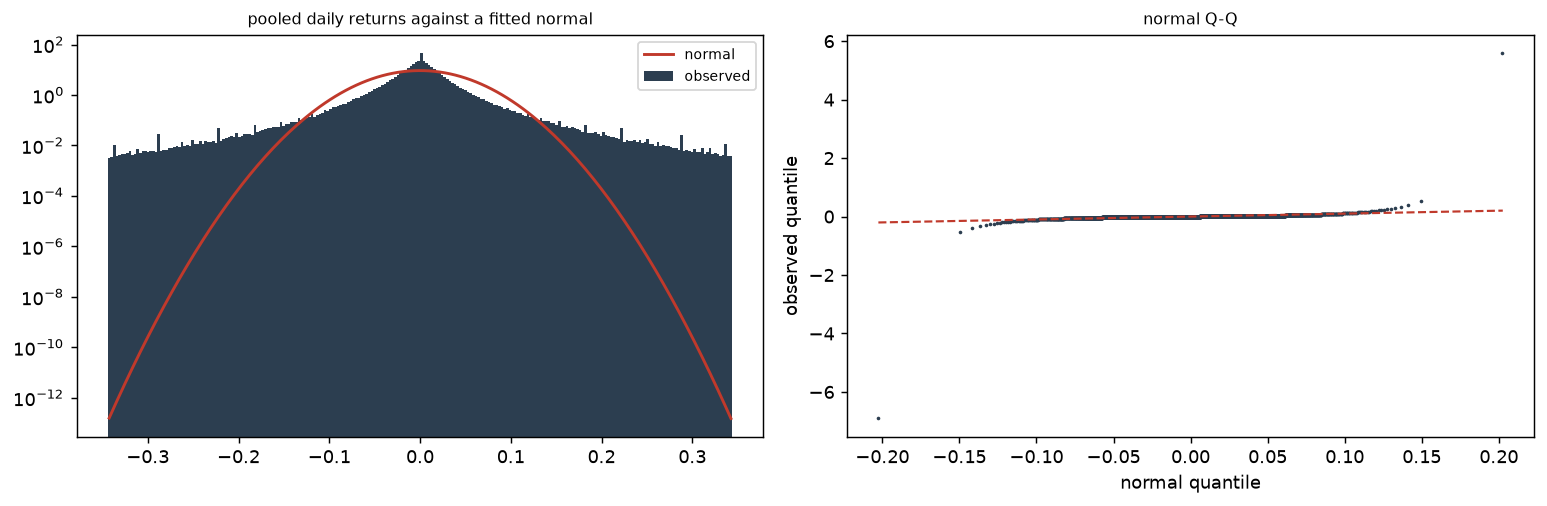

,observed once per (obs.),normal says once per (years)
move,,
3 sd,76.45,1.47
5 sd,247.70,"6,921.74"
10 sd,"1,294.86","260,389,141,081,312,231,424.00"


In [8]:
pooled = R[mask]
mu, sd = pooled.mean(), pooled.std()
edges = np.linspace(-8 * sd, 8 * sd, 241)
density, _ = np.histogram(pooled, bins=edges, density=True)
mids = (edges[:-1] + edges[1:]) / 2

sample = np.sort(rng.choice(pooled, size=min(400_000, pooled.size), replace=False))
theory = sps.norm.ppf((np.arange(1, len(sample) + 1) - 0.5) / len(sample)) * sd + mu
idx = np.unique(np.linspace(0, len(sample) - 1, 4000).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(mids, density, width=np.diff(edges), color='#2c3e50', label='observed')
axes[0].plot(mids, sps.norm.pdf(mids, mu, sd), color='#c0392b', lw=1.6, label='normal')
axes[0].set_yscale('log')
axes[0].set_title('pooled daily returns against a fitted normal', fontsize=9)
axes[0].legend(fontsize=8)
axes[1].plot(theory[idx], sample[idx], '.', ms=2, color='#2c3e50')
lim = float(np.abs(theory[idx]).max())
axes[1].plot([-lim, lim], [-lim, lim], color='#c0392b', ls='--', lw=1.2)
axes[1].set_title('normal Q-Q', fontsize=9)
axes[1].set_xlabel('normal quantile')
axes[1].set_ylabel('observed quantile')
fig.tight_layout()
plt.show()

rows = []
for k in (3, 5, 10):
    observed = float((np.abs(pooled - mu) > k * sd).mean())
    expected = float(2 * sps.norm.sf(k))
    rows.append({'move': f'{k} sd', 'observed once per (obs.)': 1 / observed,
                 'normal says once per (years)': 1 / (expected * 252)})
show_df(pd.DataFrame(rows).set_index('move'), decimals=2)

### Aggregation

Fat tails are a property of high-frequency returns, not of returns as such. Adding returns over longer
holding periods pulls the distribution back toward a normal, and the rate at which it does so is
informative: if the tails came from a handful of bad prints rather than from the dynamics of prices,
the excess would persist under aggregation instead of decaying.

,securities,periods per security,median excess kurtosis,median skewness,median ann. volatility
horizon (sessions),,,,,
1,"5,175","4,092",17.769,-0.150,0.489
5,"5,175",818,7.637,-0.230,0.473
21,"5,171",194,2.671,-0.268,0.458
63,"3,862",86,1.258,-0.354,0.394


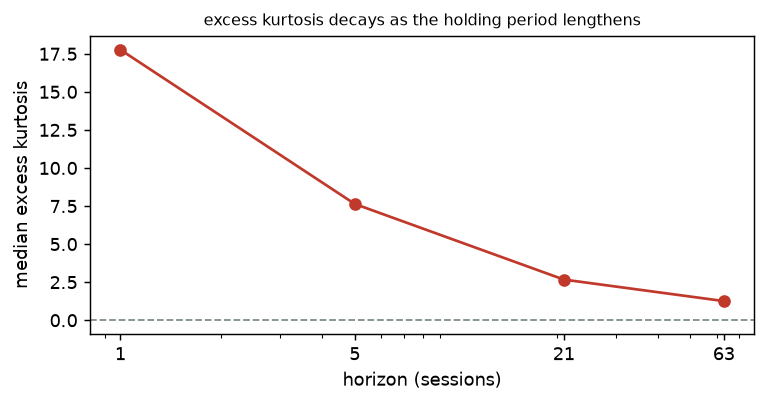

In [9]:
rows = []
for h in HORIZONS:
    values, present, count = block_returns(R, h)
    sel = count >= 30
    m = col_moments(values[:, sel], present[:, sel], count[sel])
    rows.append({'horizon (sessions)': h, 'securities': int(sel.sum()),
                 'periods per security': int(np.median(count[sel])),
                 'median excess kurtosis': float(np.nanmedian(m['exkurt'])),
                 'median skewness': float(np.nanmedian(m['skew'])),
                 'median ann. volatility': float(np.nanmedian(m['sd']) * np.sqrt(252 / h))})
aggregation = pd.DataFrame(rows).set_index('horizon (sessions)')
show_df(aggregation, decimals=3)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(aggregation.index, aggregation['median excess kurtosis'], 'o-', color='#c0392b')
ax.axhline(0, color='#7f8c8d', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xticks(list(HORIZONS))
ax.set_xticklabels([str(h) for h in HORIZONS])
ax.set_xlabel('horizon (sessions)')
ax.set_ylabel('median excess kurtosis')
ax.set_title('excess kurtosis decays as the holding period lengthens', fontsize=9)
fig.tight_layout()
plt.show()

### Mean against median

One point per security, its mean return on the horizontal axis and its median return on the vertical.
The diagonal carries the meaning. A security whose returns are symmetric sits on it, and the distance
from it measures skewness.

Below the diagonal the mean exceeds the median, which is positive skew: the typical period is worse
than the average, and a few large gains carry the whole result. Above it the mean falls short of the
median, which is negative skew: the typical period looks healthy and rare large losses do the damage.

The horizon is 21 sessions rather than 1, and the reason is the carried-forward close from section 1.
Daily returns are near-symmetric about zero and pile up on stale prints, which puts the median at
exactly zero for 46% of securities and would weld half the cloud onto a single horizontal line. At a
monthly horizon that artifact falls to 3%.

Both axes are annualized by the same factor, which is what keeps the diagonal meaningful. Note that an
annualized median is a location statistic multiplied by twelve, not a return anyone could compound.

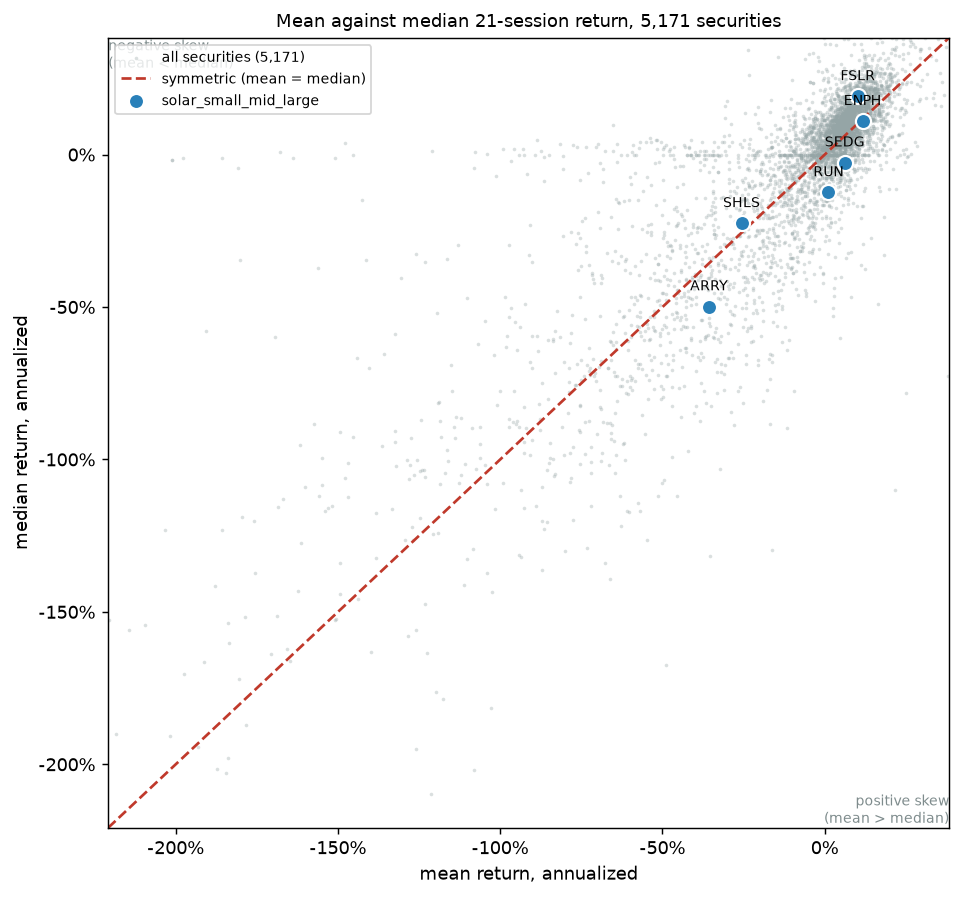

below the diagonal (positive skew)  35.4% of securities
median exactly zero                 3.2% at 21 sessions, against 46.2% at 1
not enough 21-session history to plot: NXT


*The labelled securities.*

,mean,median,skewness,periods,ann. volatility
Ticker,,,,,
ENPH,0.1170,0.1094,-0.1624,171,0.7846
FSLR,0.1019,0.1907,0.0615,235,0.5511
SEDG,0.0617,-0.0266,-0.1592,135,0.6352
RUN,0.0110,-0.1244,0.1945,131,0.7027
SHLS,-0.2565,-0.2256,0.1665,65,0.7322
ARRY,-0.3563,-0.4984,0.9007,68,0.8518


In [10]:
values, present, count = block_returns(R, SCATTER_H)
sel = count >= 30
m = col_moments(values[:, sel], present[:, sel], count[sel])
factor = 252 / SCATTER_H

scatter = pd.DataFrame({
    'mean': m['mean'] * factor, 'median': m['median'] * factor, 'skewness': m['skew'],
    'periods': m['n'], 'ann. volatility': m['sd'] * np.sqrt(factor),
}, index=pd.Index(tickers[sel], name='Ticker'))
scatter = scatter.replace([np.inf, -np.inf], np.nan).dropna(subset=['mean', 'median'])

shown = [t for t in selection if t in scatter.index]
absent = [t for t in selection if t not in scatter.index]
lo, hi = np.quantile(scatter[['mean', 'median']].to_numpy(), [0.005, 0.995])

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(scatter['mean'], scatter['median'], s=4, c='#95a5a6', alpha=0.35, linewidths=0,
           label=f'all securities ({len(scatter):,})')
ax.plot([lo, hi], [lo, hi], color='#c0392b', ls='--', lw=1.5, label='symmetric (mean = median)')
if shown:
    pts = scatter.loc[shown]
    label = SELECTION if isinstance(SELECTION, str) else 'selection'
    ax.scatter(pts['mean'], pts['median'], s=70, c='#2980b9', edgecolors='white', linewidths=1.2,
               zorder=3, label=label)
    for name, row in pts.iterrows():
        ax.annotate(name, (row['mean'], row['median']), textcoords='offset points', xytext=(0, 9),
                    ha='center', fontsize=8, zorder=4)
ax.text(hi, lo, 'positive skew\n(mean > median)', ha='right', va='bottom', fontsize=8, color='#7f8c8d')
ax.text(lo, hi, 'negative skew\n(mean < median)', ha='left', va='top', fontsize=8, color='#7f8c8d')
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_xlabel('mean return, annualized')
ax.set_ylabel('median return, annualized')
ax.set_title(f'Mean against median {SCATTER_H}-session return, {len(scatter):,} securities', fontsize=10)
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

print(f"below the diagonal (positive skew)  {(scatter['mean'] > scatter['median']).mean():.1%} of securities")
print(f"median exactly zero                 {(scatter['median'] == 0).mean():.1%} at {SCATTER_H} sessions, "
      f"against {(stats['median daily'] == 0).mean():.1%} at 1")
if absent:
    print(f'not enough {SCATTER_H}-session history to plot: {", ".join(absent)}')
show_note('The labelled securities.')
show_df(scatter.loc[shown].sort_values('mean', ascending=False), decimals=4)

## 3. Volatility

Two facts sit side by side and only make sense together. The direction of a return carries almost no
memory: knowing yesterday's return tells you next to nothing about today's, which is what an efficient
market implies. The size of a return carries a great deal of memory, decaying slowly enough to remain
visible a quarter later. Large moves cluster in time; their signs do not.

The chart plots the median autocorrelation across securities at each lag, for the signed return and for
its absolute value.

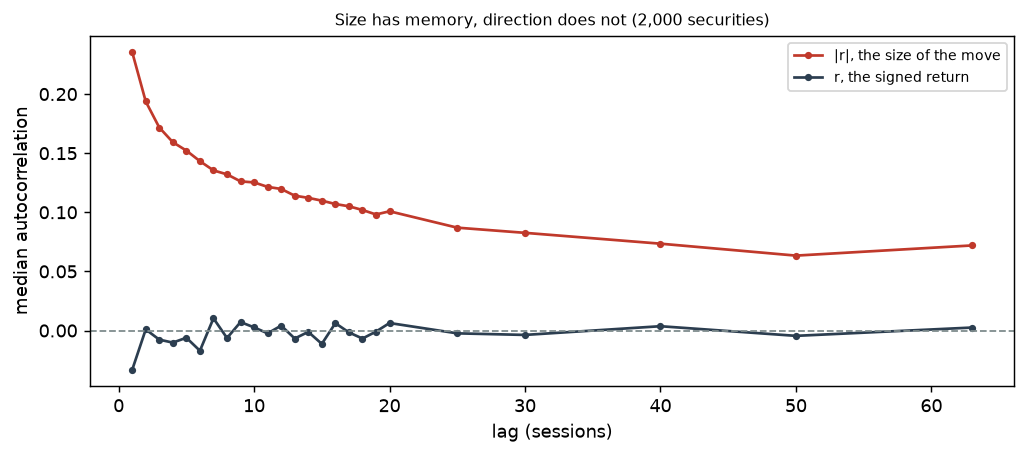

lag  1   r -0.0333   |r| +0.2355
lag 63   r +0.0025   |r| +0.0719


In [11]:
pick = rng.choice(R.shape[1], size=min(ACF_MAX, R.shape[1]), replace=False)
Rs, Ms = R[:, pick], mask[:, pick]
As = np.abs(Rs)

acf_signed = [float(np.nanmedian(col_autocorr(Rs, Ms, lag))) for lag in ACF_LAGS]
acf_absolute = [float(np.nanmedian(col_autocorr(As, Ms, lag))) for lag in ACF_LAGS]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ACF_LAGS, acf_absolute, 'o-', ms=3, color='#c0392b', label='|r|, the size of the move')
ax.plot(ACF_LAGS, acf_signed, 'o-', ms=3, color='#2c3e50', label='r, the signed return')
ax.axhline(0, color='#7f8c8d', ls='--', lw=1)
ax.set_xlabel('lag (sessions)')
ax.set_ylabel('median autocorrelation')
ax.set_title(f'Size has memory, direction does not ({len(pick):,} securities)', fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f'lag  1   r {acf_signed[0]:+.4f}   |r| {acf_absolute[0]:+.4f}')
print(f'lag 63   r {acf_signed[-1]:+.4f}   |r| {acf_absolute[-1]:+.4f}')

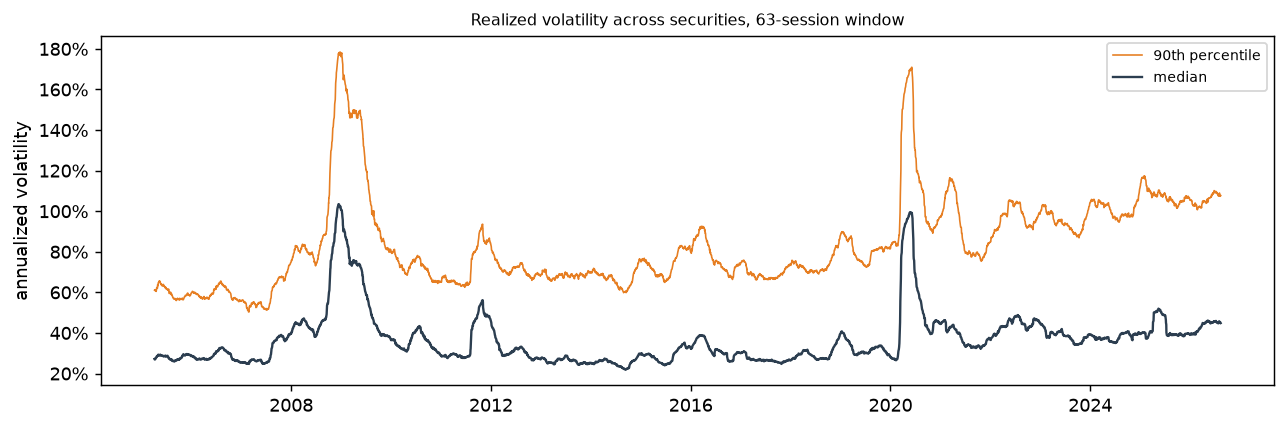

calmest  2014-09-08  22.0%
wildest  2008-12-11  103.4%


In [12]:
present = mask.astype('float64')
squared = np.where(mask, R, 0.0) ** 2
cum_sq, cum_n = np.cumsum(squared, axis=0), np.cumsum(present, axis=0)
window_sq = cum_sq[VOL_WINDOW:] - cum_sq[:-VOL_WINDOW]
window_n = cum_n[VOL_WINDOW:] - cum_n[:-VOL_WINDOW]
with np.errstate(divide='ignore', invalid='ignore'):
    realized = np.sqrt(np.where(window_n >= VOL_WINDOW * 0.6, window_sq / window_n, np.nan) * 252)

vol_dates = returns.index[VOL_WINDOW:]
vol_median = np.nanmedian(realized, axis=1)
vol_p90 = np.nanquantile(realized, 0.9, axis=1)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(vol_dates, vol_p90, color='#e67e22', lw=0.9, label='90th percentile')
ax.plot(vol_dates, vol_median, color='#2c3e50', lw=1.3, label='median')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_ylabel('annualized volatility')
ax.set_title(f'Realized volatility across securities, {VOL_WINDOW}-session window', fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f'calmest  {str(vol_dates[np.nanargmin(vol_median)])[:10]}  {np.nanmin(vol_median):.1%}')
print(f'wildest  {str(vol_dates[np.nanargmax(vol_median)])[:10]}  {np.nanmax(vol_median):.1%}')

## 4. The cross-section

How much of a security's movement is shared with everything else. This section is the summary view;
`8_pca_weights.ipynb` takes the same decomposition considerably further and should be preferred for any
question about the components themselves.

Dispersion is the standard deviation of returns across securities on a single session, which measures
how differently securities behaved that day. The composite beneath it is the mean log return across the
cross-section: the growth rate of the typical constituent, not the return of an equal-weight portfolio.
The distinction is worth keeping. A portfolio return is arithmetic, so computing one would need
`log(1 + mean(simple returns))`, and that quantity is hostage to the largest print in the cross-section
on any given day. In log space the composite is robust to a single bad price; in arithmetic space it is
not.

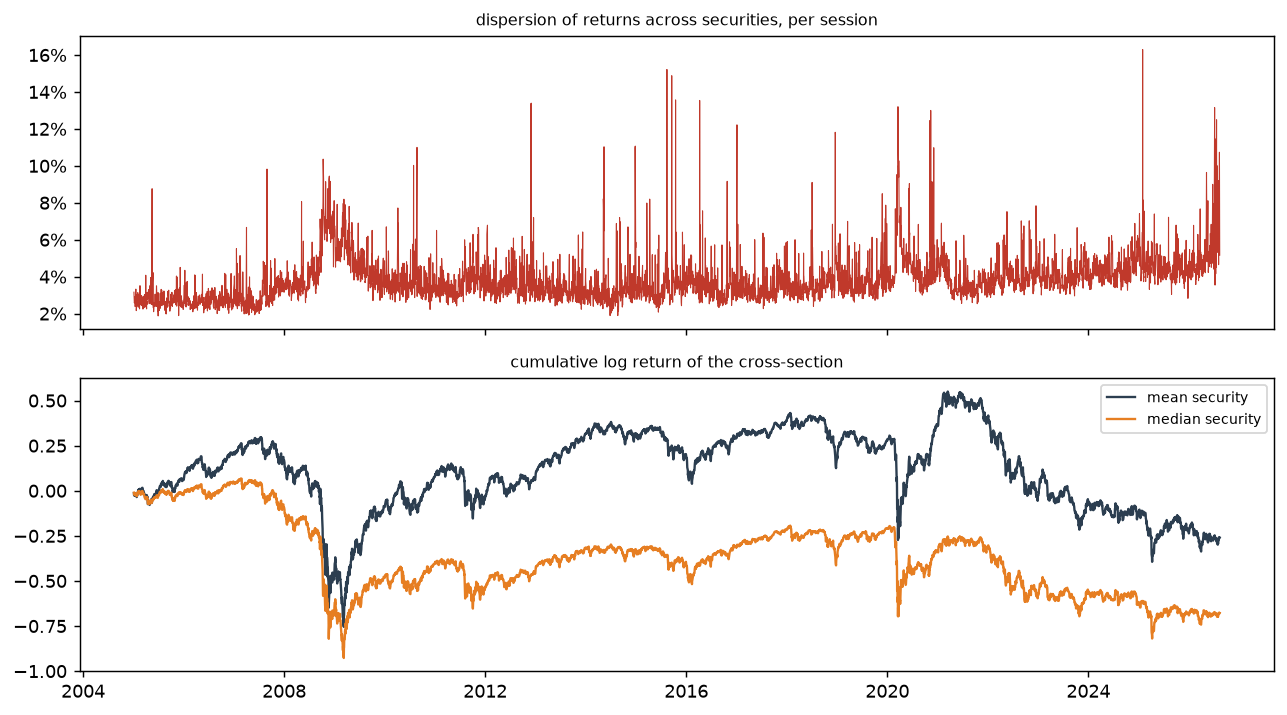

dispersion    median 3.59%, highest 16.30% on 2025-01-29
mean security   ann. return -1.20%, ann. volatility 19.12%
median security ann. return -3.14%, ann. volatility 16.43%
breadth       2,089 to 5,175 securities priced per session
largest single-session log return in the panel 11.04, a 62,499x move in one day


In [13]:
dispersion = np.nanstd(R, axis=1)
composite = np.nanmean(R, axis=1)
composite_median = np.nanmedian(R, axis=1)
breadth = mask.sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
axes[0].plot(returns.index, dispersion, color='#c0392b', lw=0.6)
axes[0].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
axes[0].set_title('dispersion of returns across securities, per session', fontsize=9)
axes[1].plot(returns.index, np.cumsum(np.where(np.isfinite(composite), composite, 0.0)),
             color='#2c3e50', lw=1.3, label='mean security')
axes[1].plot(returns.index, np.cumsum(np.where(np.isfinite(composite_median), composite_median, 0.0)),
             color='#e67e22', lw=1.3, label='median security')
axes[1].set_title('cumulative log return of the cross-section', fontsize=9)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f'dispersion    median {np.nanmedian(dispersion):.2%}, highest {np.nanmax(dispersion):.2%} '
      f'on {str(returns.index[np.nanargmax(dispersion)])[:10]}')
print(f'mean security   ann. return {np.nanmean(composite) * 252:+.2%}, '
      f'ann. volatility {np.nanstd(composite) * np.sqrt(252):.2%}')
print(f'median security ann. return {np.nanmean(composite_median) * 252:+.2%}, '
      f'ann. volatility {np.nanstd(composite_median) * np.sqrt(252):.2%}')
print(f'breadth       {breadth.min():,} to {breadth.max():,} securities priced per session')
print(f'largest single-session log return in the panel {np.nanmax(R):.2f}, '
      f'a {np.expm1(np.nanmax(R)):,.0f}x move in one day')

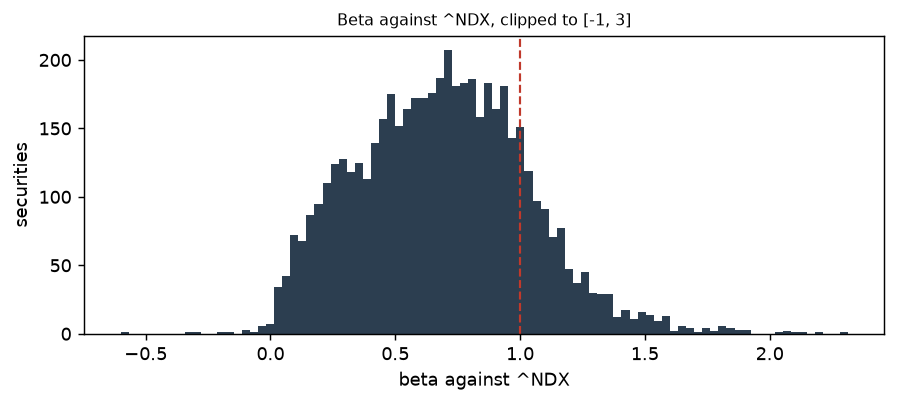

benchmark ^NDX: 5,435 of 5,435 sessions overlap the panel
beta   10th pct 0.24   median 0.68   90th pct 1.11


In [14]:
benchmark = panels.benchmark_returns(con, BENCHMARK, kind='log').reindex(returns.index)
b = benchmark.to_numpy()
both = mask & np.isfinite(b)[:, None]
n_pair = both.sum(axis=0)
x = np.where(both, b[:, None], 0.0)
y = np.where(both, R, 0.0)
sx, sy = x.sum(axis=0), y.sum(axis=0)
sxx, sxy = (x * x).sum(axis=0), (x * y).sum(axis=0)
with np.errstate(divide='ignore', invalid='ignore'):
    beta = np.where(n_pair > 60, (n_pair * sxy - sx * sy) / (n_pair * sxx - sx ** 2), np.nan)
stats['beta'] = beta

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.clip(beta[np.isfinite(beta)], -1, 3), bins=90, color='#2c3e50')
ax.axvline(1.0, color='#c0392b', ls='--', lw=1.2)
ax.set_xlabel(f'beta against {BENCHMARK}')
ax.set_ylabel('securities')
ax.set_title(f'Beta against {BENCHMARK}, clipped to [-1, 3]', fontsize=9)
fig.tight_layout()
plt.show()

print(f'benchmark {BENCHMARK}: {int(np.isfinite(b).sum()):,} of {len(b):,} sessions overlap the panel')
print(f'beta   10th pct {np.nanquantile(beta, .1):.2f}   median {np.nanmedian(beta):.2f}   '
      f'90th pct {np.nanquantile(beta, .9):.2f}')

The eigendecomposition needs a complete panel, so it runs on its own shorter window and on the
`PCA_N_TOP` most traded securities, exactly as notebook 8 does. The first eigenvalue is the market
factor: the share of all common variation that a single component absorbs.

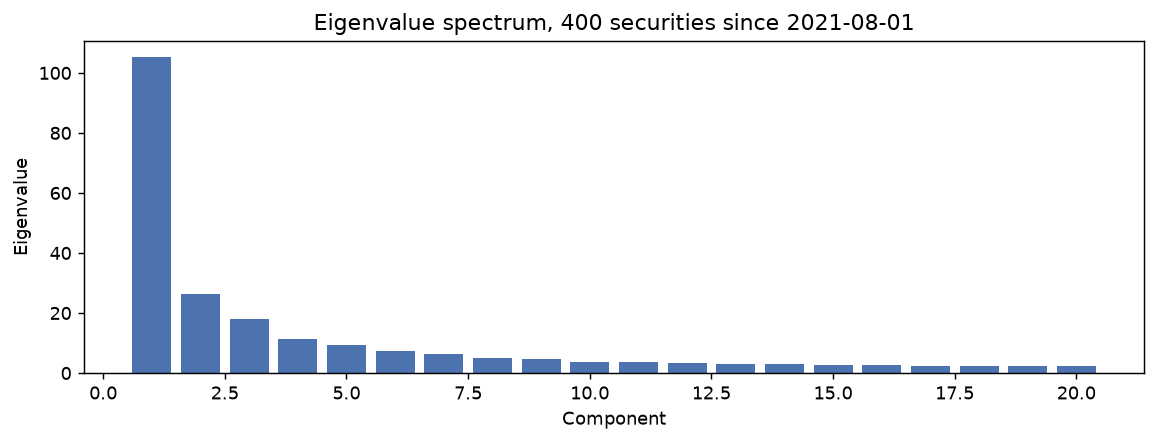

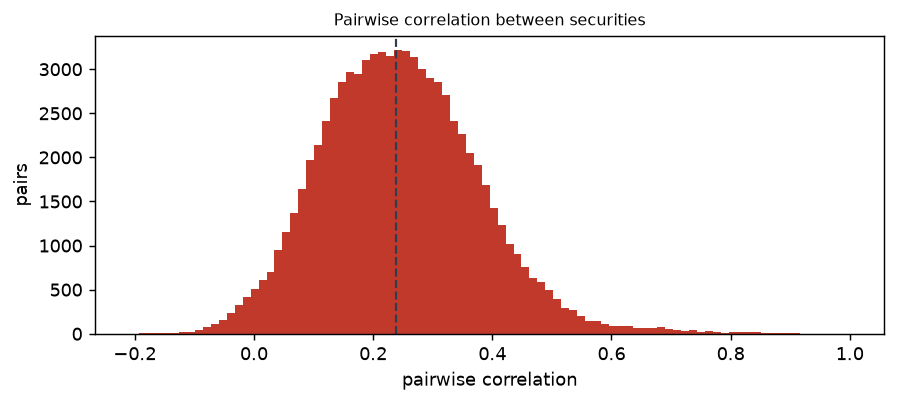

window            2021-08-02 to 2026-08-12, 1,263 sessions
PC1 26.4%   PC2 6.6%   PC3 4.5%   first ten 49.3%
pairwise correlation   median 0.239   10th pct 0.085   90th pct 0.409


In [15]:
pca_calendar = panels.trading_calendar(con, start=PCA_START, end=END)
pca_universe = panels.complete_universe(con, pca_calendar, n_top=PCA_N_TOP, rank_by='liquidity')
pca_closes = panels.close_panel(con, pca_universe, pca_calendar)
pca_std = panels.standardize(panels.returns_panel(pca_closes, kind='log'))
corr = eigen.correlation(pca_std.z)
eig = eigen.eigen_decompose(corr)
share = eigen.variance_explained(eig.values)

plot_scree(eig.values, k=20, title=f'Eigenvalue spectrum, {len(pca_universe)} securities since {PCA_START}')

off_diagonal = corr.to_numpy()[np.triu_indices(len(pca_universe), k=1)]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(off_diagonal, bins=90, color='#c0392b')
ax.axvline(float(np.median(off_diagonal)), color='#2c3e50', ls='--', lw=1.2)
ax.set_xlabel('pairwise correlation')
ax.set_ylabel('pairs')
ax.set_title('Pairwise correlation between securities', fontsize=9)
fig.tight_layout()
plt.show()

print(f'window            {pca_calendar.min().date()} to {pca_calendar.max().date()}, '
      f'{len(pca_calendar):,} sessions')
print(f'PC1 {share[0]:.1%}   PC2 {share[1]:.1%}   PC3 {share[2]:.1%}   first ten {share[:10].sum():.1%}')
print(f'pairwise correlation   median {np.median(off_diagonal):.3f}   '
      f'10th pct {np.quantile(off_diagonal, .1):.3f}   90th pct {np.quantile(off_diagonal, .9):.3f}')

## 5. By sector

The same statistics grouped by the sector recorded in `companies`. Coverage is partial, because sector
is populated from the fundamentals provider and not every priced security has fundamentals.

In [16]:
sectors = panels.sector_labels(con, list(tickers))
stats['sector'] = sectors.reindex(stats.index).to_numpy()

by_sector = (stats.dropna(subset=['sector']).groupby('sector').agg(
    securities=('sessions', 'size'),
    ann_return=('ann. return', 'median'),
    ann_volatility=('ann. volatility', 'median'),
    skewness=('skewness', 'median'),
    excess_kurtosis=('excess kurtosis', 'median'),
    beta=('beta', 'median'),
).sort_values('ann_volatility', ascending=False))

print(f'sector recorded for {stats["sector"].notna().sum():,} of {len(stats):,} securities')
show_note('Median across the securities in each sector.')
show_df(by_sector, decimals=3)

sector recorded for 5,171 of 5,175 securities


*Median across the securities in each sector.*

,securities,ann_return,ann_volatility,skewness,excess_kurtosis,beta
sector,,,,,,
Healthcare,908,-0.150,0.885,-0.049,29.505,0.725
Technology,637,0.023,0.607,-0.078,14.267,0.933
Communication Services,230,-0.034,0.601,0.010,17.261,0.737
Basic Materials,241,0.056,0.580,-0.064,10.372,0.711
Consumer Cyclical,473,0.022,0.526,-0.055,13.671,0.848
Energy,227,0.044,0.509,-0.313,17.541,0.664
Industrials,566,0.067,0.482,-0.133,13.272,0.766
Consumer Defensive,210,0.037,0.452,-0.185,17.262,0.497
,38,0.041,0.354,-0.052,19.532,0.283


## Verification

The panel mathematics is vectorized by hand, so it is checked against `scipy.stats` applied to a single
security's returns as an ordinary series: a separate implementation, reached by a different route. Three
structural checks follow, each of which would fail loudly if the vectorization drifted.

In [17]:
PROBE = 'AAPL'
column = int(np.where(tickers == PROBE)[0][0])
series = returns[PROBE].dropna()

checks = [
    ('observations', float(mom['n'][column]), float(len(series))),
    ('mean', float(mom['mean'][column]), float(series.mean())),
    ('standard deviation', float(mom['sd'][column]), float(series.std(ddof=1))),
    ('skewness', float(mom['skew'][column]), float(sps.skew(series))),
    ('excess kurtosis', float(mom['exkurt'][column]), float(sps.kurtosis(series))),
    ('median', float(mom['median'][column]), float(series.median())),
]
print(f'{PROBE}: panel-wide against scipy on the same series')
for name, got, want in checks:
    assert np.isclose(got, want, rtol=1e-9), f'{name}: panel {got} != scipy {want}'
    print(f'  ok   {name:<20} {got:>16,.9f}')

assert aggregation['median excess kurtosis'].is_monotonic_decreasing, \
    'excess kurtosis must fall as the horizon lengthens'
print('  ok   excess kurtosis decays with horizon: '
      + ' > '.join(f'{v:.1f}' for v in aggregation['median excess kurtosis']))

assert acf_absolute[0] > 5 * abs(acf_signed[0]), 'size should carry far more memory than direction'
print(f'  ok   |r| autocorrelation {acf_absolute[0]:.3f} dominates r at {acf_signed[0]:+.3f}')

assert 0.05 < share[0] < 0.60, f'PC1 share {share[0]:.1%} outside a plausible band'
print(f'  ok   PC1 absorbs {share[0]:.1%} of variance')

AAPL: panel-wide against scipy on the same series
  ok   observations          5,435.000000000
  ok   mean                      0.001060947
  ok   standard deviation        0.020185134
  ok   skewness                 -0.216222904
  ok   excess kurtosis           6.088899208
  ok   median                    0.001096278
  ok   excess kurtosis decays with horizon: 17.8 > 7.6 > 2.7 > 1.3
  ok   |r| autocorrelation 0.236 dominates r at -0.033
  ok   PC1 absorbs 26.4% of variance
